# CALABARZON Road Accident Severity — Clean End-to-End ML Pipeline
Complete 10-stage machine learning workflow following the ML Life Cycle Checklist: Problem Definition, Data Collection, Data Cleaning & Preprocessing, Exploratory Data Analysis (EDA), Feature Engineering & Selection, Model Selection, Model Training, Model Evaluation & Tuning, Model Deployment, and Model Monitoring & Maintenance.

## Stage 1: Problem Definition
- **Task Type:** Multi-class Classification
- **Target Variable:** `Accident_Severity` (`Minor`, `Moderate`, `Severe`)
- **Objective:** Predict crash severity across CALABARZON (Cavite, Laguna, Batangas, Rizal, Quezon) from pre-crash spatial, road, traffic control, temporal, weather, and vehicle features without post-crash target leakage.
- **Success Metrics:** Macro F1-Score (accounting for class imbalance across `Minor`, `Moderate`, and `Severe`) and Overall Accuracy.

## Stage 2: Data Collection
- **Input Dataset:** Uses the raw `CALABARZON_Road_Accident_Severity_Extra_Dirty_Dataset-v2.csv` when available, otherwise the provided cleaned CSV.
- **Reference Grounding:** Aligned with regional CALABARZON road traffic accident criticality findings and PNP Highway Patrol Group (PNP-HPG) crash distributions.
- **Schema Columns:** `Accident_ID`, `Province`, `City_Municipality`, `Barangay`, `Street_Road`, `Intersection`, `Traffic_Light_Present`, `Traffic_Light_Operational`, `Traffic_Light_Installation_Year`, `Accident_Date`, `Accident_Time`, `Weather`, `Lighting_Condition`, `Road_Surface`, `Road_Type`, `Vehicle_Type`, `Collision_Type`, `Number_of_Vehicles`, `Number_of_Injured`, `Number_of_Fatalities`, `Accident_Severity`.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

data_candidates = [
    Path('CALABARZON_Road_Accident_Severity_Extra_Dirty_Dataset-v2.csv'),
    Path('CALABARZON_Road_Accident_Severity_Cleaned (1).csv'),
    Path('CALABARZON_Road_Accident_Severity_Cleaned.csv'),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    expected = ', '.join(path.name for path in data_candidates)
    raise FileNotFoundError(f'No input dataset found. Place one of these files beside the notebook: {expected}')

df_raw = pd.read_csv(data_path)
print(f'Loaded {data_path.name} | Shape: {df_raw.shape}')
df_raw.head()

Loaded CALABARZON_Road_Accident_Severity_Cleaned (1).csv | Shape: (2000, 23)


,Accident_ID,Province,City_Municipality,Barangay,Street_Road,Intersection,Traffic_Light_Present,Traffic_Light_Operational,Traffic_Light_Installation_Year,Accident_Date,...,Road_Surface,Road_Type,Vehicle_Type,Collision_Type,Number_of_Vehicles,Number_of_Injured,Number_of_Fatalities,Accident_Severity,Accident_Date_Parsed,Accident_Time_Parsed
0,CAL-00001,Rizal,Rodriguez,San Jose,Rodriguez Highway,Yes,No,Not Applicable,Not Applicable,2026-03-12,...,Dry,Provincial Road,Motorcycle,Sideswipe,2.0,0.0,0.0,Minor,2026-03-12,1900-01-01 07:42:00
1,CAL-00002,Laguna,Pagsanjan,Poblacion,Pagsanjan-Cavinti Road,No,Yes,Yes,2012,2024-09-09,...,Dry,Provincial Road,Car,Sideswipe,2.0,1.0,0.0,Minor,2024-09-09,1900-01-01 13:38:00
2,CAL-00003,Rizal,Cainta,San Isidro,Ortigas Avenue Extension,No,No,Not Applicable,Not Applicable,2026-08-11,...,Dry,National Highway,Motorcycle,Rear-End,2.0,0.0,0.0,Minor,2026-08-11,1900-01-01 15:41:00
3,CAL-00004,Batangas,Nasugbu,Wawa,Tagaytay-Nasugbu Highway,Yes,Yes,Yes,2017,2025-06-19,...,Dry,National Highway,Motorcycle,Pedestrian-Related,1.0,0.0,0.0,Minor,2025-06-19,1900-01-01 18:22:00
4,CAL-00005,Cavite,Silang,San Vicente,Tagaytay-Sta. Rosa Road,Yes,Yes,Yes,2013,2023-06-10,...,Dry,National Highway,Truck,Rear-End,3.0,1.0,0.0,Minor,2023-06-10,1900-01-01 21:10:00


## Stage 3: Data Cleaning and Preprocessing
Normalizes missing tokens and categories, keeps the most complete duplicate record, parses mixed date/time formats, validates numeric counts and traffic-light fields, and retains rows with missing dates/times for imputation. Rows without a valid target label are removed before exporting `CALABARZON_Road_Accident_Severity_Cleaned.csv`.

In [2]:
def clean_accident_data(df_in: pd.DataFrame) -> pd.DataFrame:
    required_columns = {
        'Accident_ID', 'Province', 'City_Municipality', 'Barangay', 'Street_Road',
        'Intersection', 'Traffic_Light_Present', 'Traffic_Light_Operational',
        'Traffic_Light_Installation_Year', 'Accident_Date', 'Accident_Time',
        'Weather', 'Lighting_Condition', 'Road_Surface', 'Road_Type',
        'Vehicle_Type', 'Collision_Type', 'Number_of_Vehicles',
        'Number_of_Injured', 'Number_of_Fatalities', 'Accident_Severity'
    }
    missing_columns = required_columns.difference(df_in.columns)
    if missing_columns:
        raise ValueError(f'Dataset is missing required columns: {sorted(missing_columns)}')

    df = df_in.drop(columns=['Accident_Date_Parsed', 'Accident_Time_Parsed'], errors='ignore').copy()
    na_tokens = {'', 'none', 'unknown', 'n/a', 'na', 'null', '?', '--', '-', '--:--', 'invalid', 'error'}
    for col in df.select_dtypes(include=['object', 'string']).columns:
        values = df[col].astype('string').str.strip()
        df[col] = values.mask(values.str.casefold().isin(na_tokens))

    df = df.drop_duplicates().copy()
    df['_row_order'] = np.arange(len(df))
    df['_completeness'] = df.notna().sum(axis=1)
    with_id = df[df['Accident_ID'].notna()].sort_values(
        ['_completeness', '_row_order'], ascending=[False, True], kind='stable'
    ).drop_duplicates(subset='Accident_ID', keep='first')
    without_id = df[df['Accident_ID'].isna()]
    df = pd.concat([with_id, without_id]).sort_values('_row_order', kind='stable')
    df = df.drop(columns=['_row_order', '_completeness'])

    title_columns = [
        'Province', 'City_Municipality', 'Barangay', 'Street_Road', 'Weather',
        'Lighting_Condition', 'Road_Surface', 'Road_Type', 'Vehicle_Type',
        'Collision_Type', 'Accident_Severity'
    ]
    for col in title_columns:
        df[col] = df[col].str.title()

    yes_no_map = {
        'yes': 'Yes', 'y': 'Yes', 'true': 'Yes', '1': 'Yes',
        'no': 'No', 'n': 'No', 'false': 'No', '0': 'No',
        'not applicable': 'Not Applicable', 'not applicable.': 'Not Applicable'
    }
    for col in ['Intersection', 'Traffic_Light_Present', 'Traffic_Light_Operational']:
        values = df[col].astype('string').str.strip()
        df[col] = values.str.casefold().map(yes_no_map).fillna(values.str.title())

    df['Accident_Severity'] = df['Accident_Severity'].replace({'Fatal': 'Severe', 'Critical': 'Severe'})
    df['Accident_Date_Parsed'] = pd.to_datetime(
        df['Accident_Date'], format='mixed', errors='coerce'
    )
    df['Accident_Time_Parsed'] = pd.to_datetime(
        df['Accident_Time'], format='mixed', errors='coerce'
    )

    number_words = {
        'zero': '0', 'one': '1', 'two': '2', 'three': '3', 'four': '4',
        'five': '5', 'six': '6', 'seven': '7', 'eight': '8', 'nine': '9', 'ten': '10'
    }
    for col in ['Number_of_Vehicles', 'Number_of_Injured', 'Number_of_Fatalities']:
        values = df[col].astype('string').str.casefold().replace(number_words)
        numeric = pd.to_numeric(values, errors='coerce')
        valid_counts = numeric.ge(0) & numeric.mod(1).eq(0)
        df[col] = numeric.where(valid_counts.fillna(False)).astype('Int64')

    year_values = df['Traffic_Light_Installation_Year'].astype('string').str.extract(r'(\d{4})', expand=False)
    installation_year = pd.to_numeric(year_values, errors='coerce')
    valid_year = installation_year.between(1980, pd.Timestamp.now().year)
    df['Traffic_Light_Installation_Year'] = installation_year.where(valid_year.fillna(False)).astype('Int64')

    no_light = df['Traffic_Light_Present'].eq('No')
    df.loc[no_light, 'Traffic_Light_Operational'] = 'Not Applicable'
    df.loc[no_light, 'Traffic_Light_Installation_Year'] = pd.NA

    valid_severity = df['Accident_Severity'].isin(['Minor', 'Moderate', 'Severe'])
    df = df.loc[valid_severity].copy()
    if df.empty:
        raise ValueError('No rows with a valid Accident_Severity remain after cleaning.')
    return df

df_clean = clean_accident_data(df_raw)
df_clean.to_csv('CALABARZON_Road_Accident_Severity_Cleaned.csv', index=False)
print('Cleaned Shape:', df_clean.shape)
print('Rows removed:', len(df_raw) - len(df_clean))
print('Remaining missing values:', int(df_clean.isna().sum().sum()))

Cleaned Shape: (2000, 23)
Rows removed: 0
Remaining missing values: 1387


## Stage 4: Exploratory Data Analysis (EDA)
Summarizes numeric distributions and examines crash patterns in six separate, individually numbered figures.

In [3]:
print(df_clean[['Number_of_Vehicles', 'Number_of_Injured', 'Number_of_Fatalities']].describe())

       Number_of_Vehicles  Number_of_Injured  Number_of_Fatalities
count              2000.0             2000.0                2000.0
mean                1.916             0.7425                0.0425
std              0.666458            0.95218              0.220722
min                   1.0                0.0                   0.0
25%                   2.0                0.0                   0.0
50%                   2.0                0.0                   0.0
75%                   2.0                1.0                   0.0
max                   4.0                4.0                   2.0


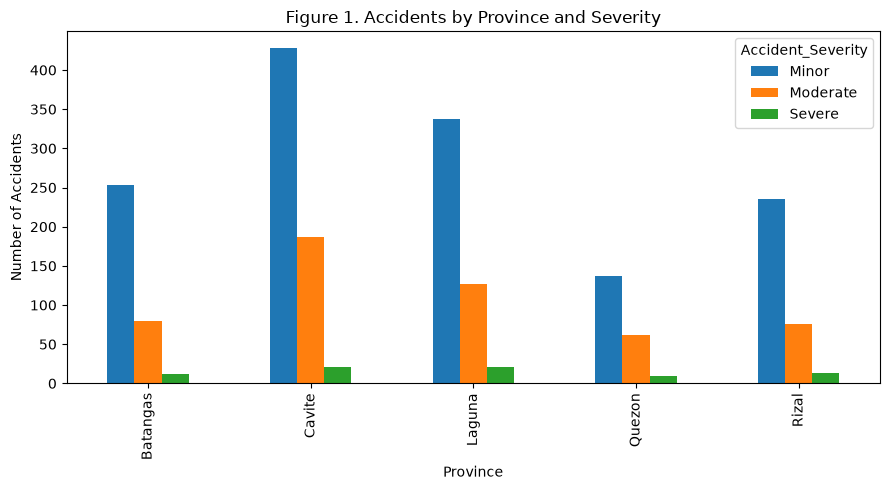

In [4]:
# Figure 1: Accidents by Province and Severity
pd.crosstab(df_clean['Province'], df_clean['Accident_Severity'])[['Minor', 'Moderate', 'Severe']].plot(kind='bar', figsize=(9, 5))
plt.title('Figure 1. Accidents by Province and Severity')
plt.xlabel('Province')
plt.ylabel('Number of Accidents')
plt.tight_layout()
plt.show()

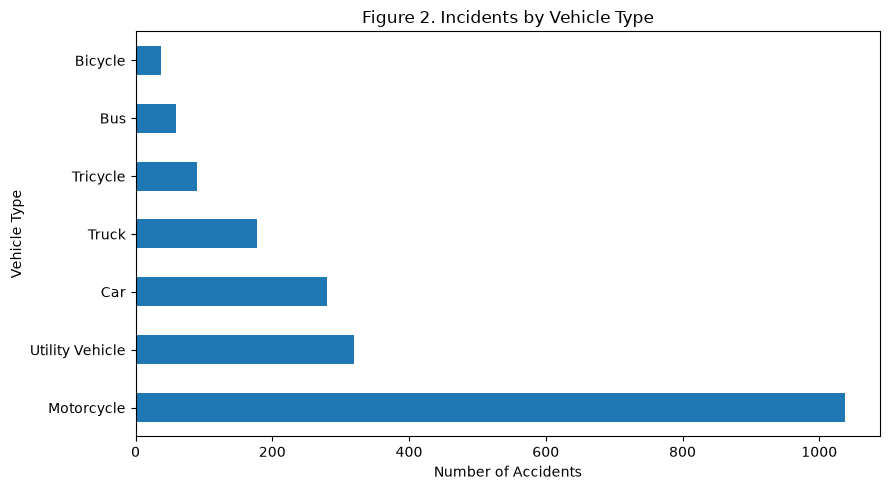

In [5]:
# Figure 2: Incidents by Vehicle Type
df_clean['Vehicle_Type'].value_counts().plot(kind='barh', figsize=(9, 5))
plt.title('Figure 2. Incidents by Vehicle Type')
plt.xlabel('Number of Accidents')
plt.ylabel('Vehicle Type')
plt.tight_layout()
plt.show()

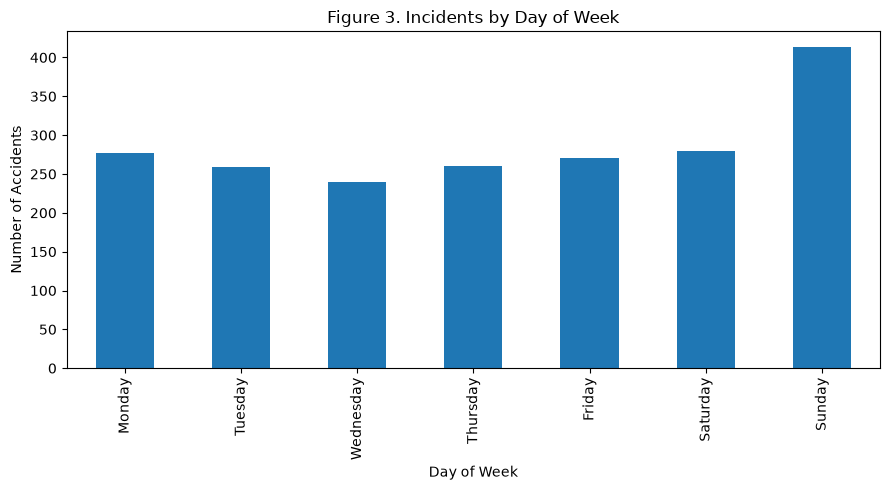

In [6]:
# Figure 3: Incidents by Day of Week
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_clean['Accident_Date_Parsed'].dt.day_name().value_counts().reindex(dow_order).plot(kind='bar', figsize=(9, 5))
plt.title('Figure 3. Incidents by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Accidents')
plt.tight_layout()
plt.show()

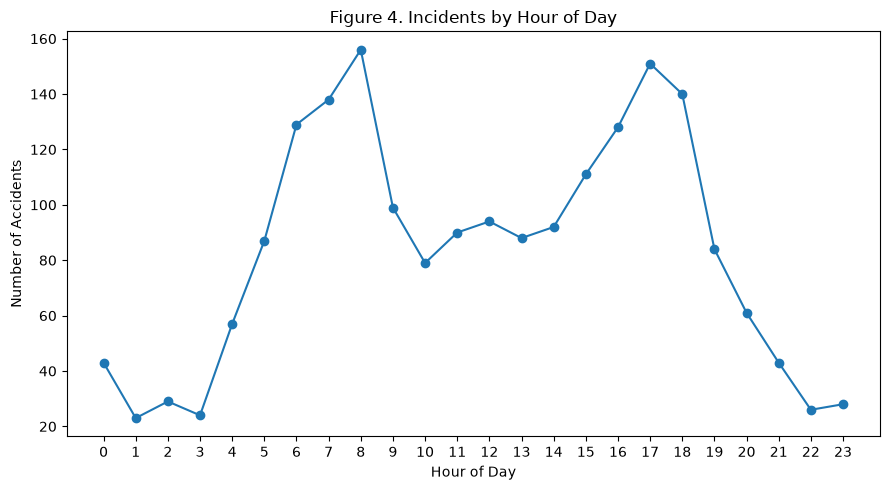

In [7]:
# Figure 4: Incidents by Hour of Day
df_clean['Accident_Time_Parsed'].dt.hour.value_counts().sort_index().plot(kind='line', marker='o', figsize=(9, 5))
plt.title('Figure 4. Incidents by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Accidents')
plt.xticks(range(24))
plt.tight_layout()
plt.show()

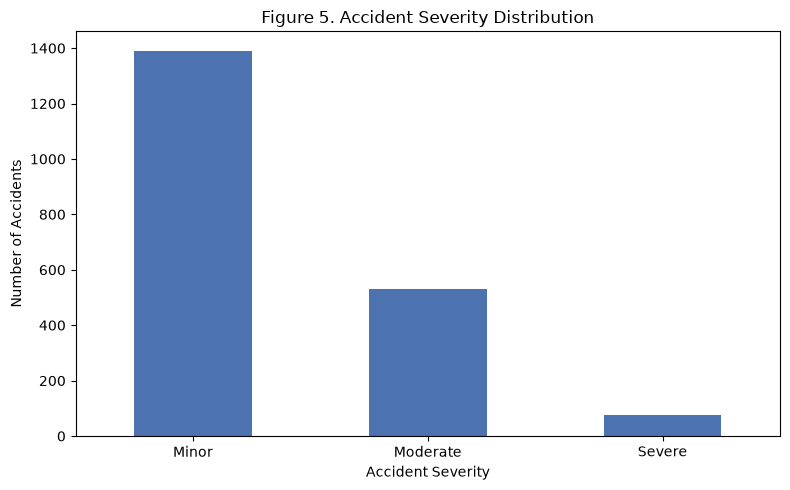

In [8]:
# Figure 5: Accident Severity Distribution
severity_order = ['Minor', 'Moderate', 'Severe']
df_clean['Accident_Severity'].value_counts().reindex(severity_order, fill_value=0).plot(kind='bar', figsize=(8, 5), color='#4c72b0')
plt.title('Figure 5. Accident Severity Distribution')
plt.xlabel('Accident Severity')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

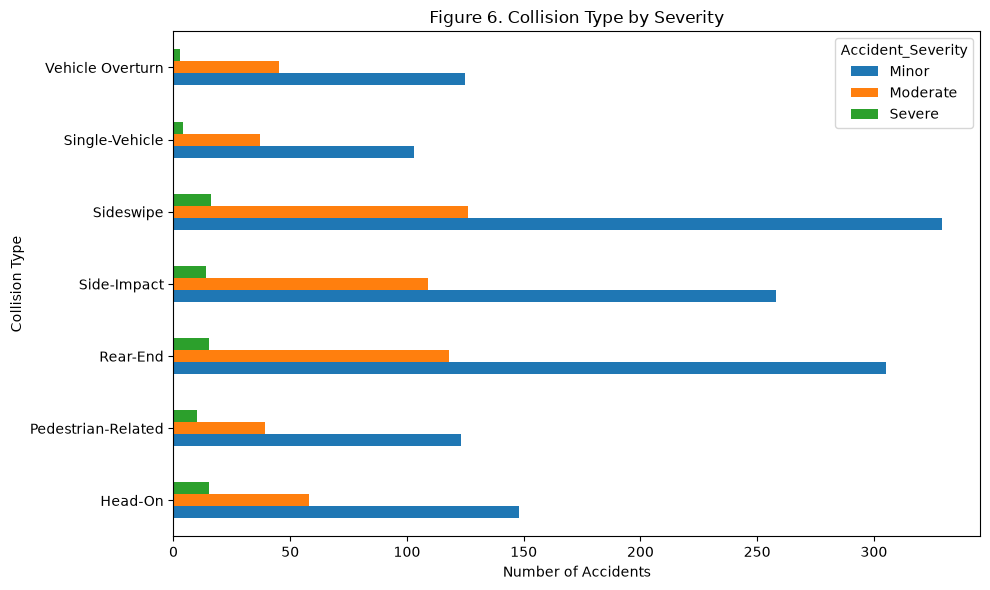

In [9]:
# Figure 6: Collision Type by Severity
collision_severity = pd.crosstab(df_clean['Collision_Type'], df_clean['Accident_Severity'])
collision_severity = collision_severity.reindex(columns=['Minor', 'Moderate', 'Severe'], fill_value=0)
collision_severity.plot(kind='barh', figsize=(10, 6))
plt.title('Figure 6. Collision Type by Severity')
plt.xlabel('Number of Accidents')
plt.ylabel('Collision Type')
plt.tight_layout()
plt.show()

## Stage 5: Feature Engineering and Selection
- **Created Features:** `Day_of_Week`, `Month`, `Is_Weekend`, `Hour`, `Is_Rush_Hour`, `Is_Night`, and `Traffic_Light_Installed_Flag`. Missing date/time values remain missing for pipeline imputation.
- **Leakage Prevention:** Drops post-crash casualty columns (`Number_of_Injured`, `Number_of_Fatalities`) from predictors; imputes missing feature values and applies `OneHotEncoder(handle_unknown='ignore')` and `StandardScaler()` inside a `ColumnTransformer`.

In [10]:
df_feat = df_clean.copy()
parsed_dates = df_feat['Accident_Date_Parsed']
df_feat['Day_of_Week'] = parsed_dates.dt.day_name()
df_feat['Month'] = parsed_dates.dt.month
day_of_week = parsed_dates.dt.day_of_week
df_feat['Is_Weekend'] = day_of_week.isin([5, 6]).astype(float).where(parsed_dates.notna())
df_feat['Hour'] = df_feat['Accident_Time_Parsed'].dt.hour
df_feat['Is_Rush_Hour'] = df_feat['Hour'].isin([7, 8, 9, 17, 18, 19]).astype(float).where(df_feat['Hour'].notna())
df_feat['Is_Night'] = (~df_feat['Hour'].between(6, 18)).astype(float).where(df_feat['Hour'].notna())
df_feat['Traffic_Light_Installed_Flag'] = df_feat['Traffic_Light_Present'].map({'Yes': 1.0, 'No': 0.0})

cat_cols = [
    'Province', 'City_Municipality', 'Intersection', 'Traffic_Light_Present',
    'Traffic_Light_Operational', 'Weather', 'Lighting_Condition',
    'Road_Surface', 'Road_Type', 'Vehicle_Type', 'Collision_Type', 'Day_of_Week'
]
num_cols = [
    'Number_of_Vehicles', 'Month', 'Is_Weekend', 'Hour',
    'Is_Rush_Hour', 'Is_Night', 'Traffic_Light_Installed_Flag',
    'Traffic_Light_Installation_Year'
]

X = df_feat[cat_cols + num_cols]
y = df_feat['Accident_Severity']

preprocessor = ColumnTransformer([
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols)
])

## Stage 6: Model Selection
Compares `LogisticRegression`, `RandomForestClassifier`, and `GradientBoostingClassifier` using stratified 5-fold cross-validation on the training partition. Selects the model with the highest mean macro F1; the held-out test partition is not used for selection.

In [11]:
class_counts = y.value_counts()
if len(class_counts) < 2 or class_counts.min() < 3:
    raise ValueError('Each severity class needs at least 3 records for a stratified holdout and cross-validation.')

test_size = max(0.20, len(class_counts) / len(y))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=42, stratify=y
)

candidates = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

n_splits = min(5, int(y_train.value_counts().min()))
if n_splits < 2:
    raise ValueError('Not enough training records in the smallest severity class for cross-validation.')
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
selection_results = []
for name, clf in candidates.items():
    pipe = Pipeline([('prep', preprocessor), ('model', clf)])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro').mean()
    selection_results.append({'Model': name, 'CV_Macro_F1': cv_f1})

selection_results = pd.DataFrame(selection_results).sort_values('CV_Macro_F1', ascending=False)
display(selection_results)
selected_model_name = selection_results.iloc[0]['Model']
print(f"Selected model: {selected_model_name}")

,Model,CV_Macro_F1
1,Random Forest,0.288618
2,Gradient Boosting,0.287858
0,Logistic Regression,0.283033


Selected model: Random Forest


## Stage 7: Model Training
Fits the selected model on the training partition using a pipeline, keeping preprocessing fitted only on training data.

In [12]:
selected_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', candidates[selected_model_name])
])
selected_pipeline.fit(X_train, y_train)
print(f"Trained {selected_model_name} on {len(X_train)} training records.")

Trained Random Forest on 1600 training records.


## Stage 8: Model Evaluation and Tuning
Tunes `RandomForestClassifier` with `RandomizedSearchCV` (`n_iter=12`, stratified CV on `f1_macro`) and reports test accuracy, macro F1, classification report, and confusion matrix.

In [ ]:
rf_pipeline = Pipeline([('prep', preprocessor), ('model', RandomForestClassifier(random_state=42))])
param_distributions = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 8, 15, 25],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

search = RandomizedSearchCV(
    rf_pipeline, param_distributions=param_distributions,
    n_iter=12, scoring='f1_macro', cv=cv, random_state=42, n_jobs=1
)
search.fit(X_train, y_train)
best_pipe = search.best_estimator_
y_pred = best_pipe.predict(X_test)

print('Best Parameters:', search.best_params_)
print('Tuned Test Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Tuned Test Macro F1:', round(f1_score(y_test, y_pred, average='macro'), 4))
print('\nClassification Report:\n', classification_report(y_test, y_pred, labels=['Minor', 'Moderate', 'Severe'], zero_division=0))
labels = ['Minor', 'Moderate', 'Severe']
cm = confusion_matrix(y_test, y_pred, labels=labels)
print('\nConfusion Matrix:\n', pd.DataFrame(cm, index=labels, columns=labels))

## Stage 9: Model Deployment Plan
- **Model Serialization:** Save the fitted `best_pipe` (`ColumnTransformer` + tuned `RandomForestClassifier`) with `joblib` (`calabarzon_severity_model.joblib`).
- **Inference Service:** Serve batch or FastAPI predictions over validated pre-crash input fields, returning predicted severity and class probabilities to support LGU and traffic safety corridor prioritization.

## Stage 10: Model Monitoring and Maintenance
- **Drift & Performance Tracking:** Monitor feature drift (motorcycle share, wet/rainy conditions, traffic signal status, seasonal/holiday travel peaks) and quarterly Macro F1 / accuracy against verified outcomes.
- **Retraining & Limitations:** Retrain quarterly or upon drift alerts; note that class imbalance (`Minor` majority vs. `Severe` minority) limits minority-class recall from pre-crash fields alone, so outputs should complement rather than replace formal incident investigation.